# Seleccion de hiperparametros

Se predice la calidad del vino tinto (0-10) con un `Pipeline(StandardScaler, ElasticNet)`. Los hiperparametros `alpha` y `l1_ratio` se eligen con `GridSearchCV` (validacion cruzada de 5 particiones) usando solo el conjunto de entrenamiento. La logica esta en `src/train_estimator.py`.

In [1]:
import pickle
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

sys.path.append(str(Path('..') / 'src'))
import train_estimator as te

df = te.load_dataset()
df.shape

(1599, 12)

## Datos

In [2]:
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.320,1.741,4.600,7.100,7.900,9.200,15.900
volatile acidity,1599.0,0.528,0.179,0.120,0.390,0.520,0.640,1.580
citric acid,1599.0,0.271,0.195,0.000,0.090,0.260,0.420,1.000
residual sugar,1599.0,2.539,1.410,0.900,1.900,2.200,2.600,15.500
chlorides,1599.0,0.087,0.047,0.012,0.070,0.079,0.090,0.611
free sulfur dioxide,1599.0,15.875,10.460,1.000,7.000,14.000,21.000,72.000
total sulfur dioxide,1599.0,46.468,32.895,6.000,22.000,38.000,62.000,289.000
density,1599.0,0.997,0.002,0.990,0.996,0.997,0.998,1.004
pH,1599.0,3.311,0.154,2.740,3.210,3.310,3.400,4.010
sulphates,1599.0,0.658,0.170,0.330,0.550,0.620,0.730,2.000


In [3]:
df[te.TARGET].value_counts().sort_index().plot.bar(xlabel='quality', ylabel='vinos', title='Distribucion de la calidad');

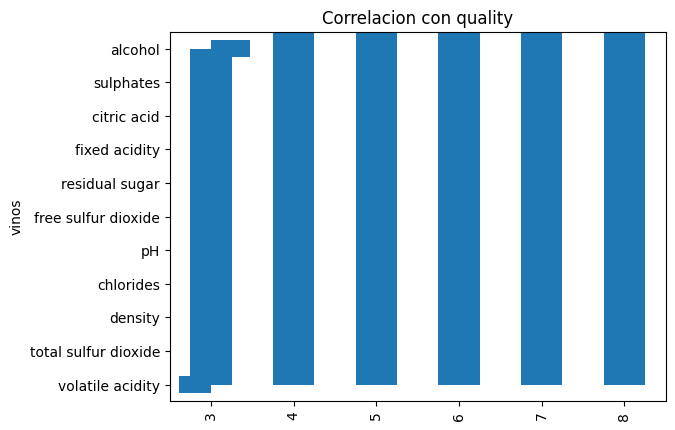

In [4]:
df.corr()[te.TARGET].drop(te.TARGET).sort_values().plot.barh(title='Correlacion con quality');

## Busqueda en malla

Se ejecuta el script completo: separa 25% para prueba, ajusta el `GridSearchCV` y guarda `submission/estimator.pkl`.

In [5]:
estimator = te.main()

Mejores hiperparametros:
  regressor__alpha: 0.003162
  regressor__l1_ratio: 1
MSE validacion cruzada: 0.4182
train mse=0.4110 mae=0.4966 r2=0.3720
test mse=0.4403 mae=0.5172 r2=0.3110
Estimador guardado en C:\Users\danie\dev\Analitica Predictiva\std-daniel-gonzalez-henao\PRE_09_hiperparametros\submission\estimator.pkl


In [6]:
resultados = pd.DataFrame(estimator.cv_results_)
malla = resultados.pivot_table(
    index='param_regressor__alpha',
    columns='param_regressor__l1_ratio',
    values='mean_test_score',
).mul(-1)
malla.round(4)

param_regressor__l1_ratio,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0
param_regressor__alpha,,,,,,,,,,
0.000100,0.4186,0.4186,0.4186,0.4186,0.4186,0.4186,0.4186,0.4186,0.4185,0.4185
0.000316,0.4186,0.4186,0.4185,0.4185,0.4185,0.4185,0.4185,0.4185,0.4185,0.4185
0.001000,0.4185,0.4185,0.4185,0.4185,0.4185,0.4184,0.4184,0.4184,0.4184,0.4184
0.003162,0.4185,0.4184,0.4184,0.4183,0.4183,0.4183,0.4182,0.4182,0.4182,0.4182
0.010000,0.4184,0.4183,0.4183,0.4183,0.4183,0.4185,0.4186,0.4188,0.4189,0.4191
0.031623,0.4186,0.4190,0.4195,0.4202,0.4208,0.4213,0.4220,0.4228,0.4236,0.4246
0.100000,0.4215,0.4236,0.4263,0.4302,0.4350,0.4397,0.4431,0.4462,0.4494,0.4529
0.316228,0.4375,0.4527,0.4654,0.4795,0.4966,0.5136,0.5319,0.5535,0.5772,0.5952
1.000000,0.5074,0.5571,0.6114,0.6540,0.6559,0.6559,0.6559,0.6559,0.6559,0.6559


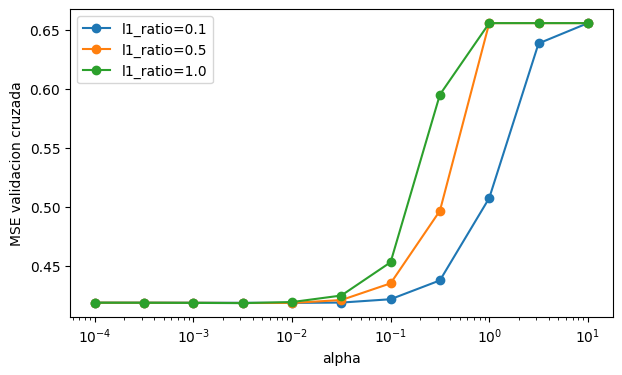

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
for l1 in [0.1, 0.5, 1.0]:
    serie = malla.loc[:, [c for c in malla.columns if abs(c - l1) < 1e-9][0]]
    ax.plot(serie.index, serie.values, marker='o', label=f'l1_ratio={l1}')
ax.set_xscale('log')
ax.set_xlabel('alpha')
ax.set_ylabel('MSE validacion cruzada')
ax.legend();

Con `alpha` pequeno el MSE es casi plano: la regularizacion apenas cambia el modelo. A partir de `alpha` cercano a 0.1 el error sube rapido porque los coeficientes se encogen demasiado.

## Modelo elegido

volatile acidity       -0.1691
pH                     -0.1010
total sulfur dioxide   -0.0974
chlorides              -0.0826
citric acid            -0.0329
density                -0.0034
fixed acidity           0.0000
residual sugar          0.0153
free sulfur dioxide     0.0405
sulphates               0.1511
alcohol                 0.3298
dtype: float64

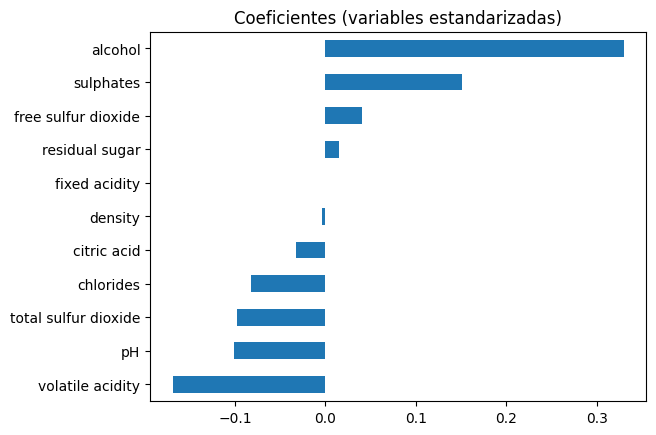

In [8]:
coef = pd.Series(
    estimator.best_estimator_.named_steps['regressor'].coef_,
    index=df.drop(columns=te.TARGET).columns,
).sort_values()
coef.plot.barh(title='Coeficientes (variables estandarizadas)');
coef.round(4)

In [9]:
with open(te.ESTIMATOR_PATH, 'rb') as archivo:
    cargado = pickle.load(archivo)
cargado.predict(df.drop(columns=te.TARGET).head()).round(2)

array([5.03, 5.22, 5.27, 5.65, 5.03])